# 04 - Evaluation and Explainability

**Owner:** Rohan  
**Part:** E (Evaluation + Grad-CAM + t-SNE)

This notebook documents the evaluation and explainability experiments using existing results. No model retraining is performed.


## 1. Model Evaluation

MobileNetV2 was evaluated on 4,050 EuroSAT test images.

- Test Accuracy: 98.30%
- Macro-F1: 98.20%
- Correct Predictions: 3,981
- Incorrect Predictions: 69


In [1]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Works whether Jupyter starts in the repo folder or in notebooks/.
project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
os.chdir(project_root)
RESULTS = project_root / "results"
FIGURES = RESULTS / "figures"

report = pd.read_csv(
    RESULTS / "mobilenet_v2_full_frac1_seed0_classification_report.csv",
    index_col=0
)
cm = pd.read_csv(
    RESULTS / "mobilenet_v2_full_frac1_seed0_confusion_matrix.csv",
    index_col=0
)

print("Classification Report")
display(report)

print("Confusion Matrix")
display(cm)


Classification Report


,precision,recall,f1-score,support
AnnualCrop,0.982022,0.971111,0.976536,450.000000
Forest,0.993363,0.997778,0.995565,450.000000
HerbaceousVegetation,0.986517,0.975556,0.981006,450.000000
Highway,0.973475,0.978667,0.976064,375.000000
Industrial,0.989247,0.981333,0.985274,375.000000
Pasture,0.951299,0.976667,0.963816,300.000000
PermanentCrop,0.967742,0.960000,0.963855,375.000000
Residential,0.988962,0.995556,0.992248,450.000000
River,0.989305,0.986667,0.987984,375.000000
SeaLake,0.995575,1.000000,0.997783,450.000000


Confusion Matrix


,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
AnnualCrop,437,0,0,0,0,5,7,0,0,1
Forest,0,449,1,0,0,0,0,0,0,0
HerbaceousVegetation,0,0,439,1,0,5,5,0,0,0
Highway,0,0,0,367,1,2,0,1,4,0
Industrial,0,0,1,3,368,0,0,3,0,0
Pasture,4,1,1,0,0,293,0,0,0,1
PermanentCrop,3,1,3,3,1,3,360,1,0,0
Residential,0,0,0,0,2,0,0,448,0,0
River,1,1,0,3,0,0,0,0,370,0
SeaLake,0,0,0,0,0,0,0,0,0,450


## 2. Confusion Matrix Visualization

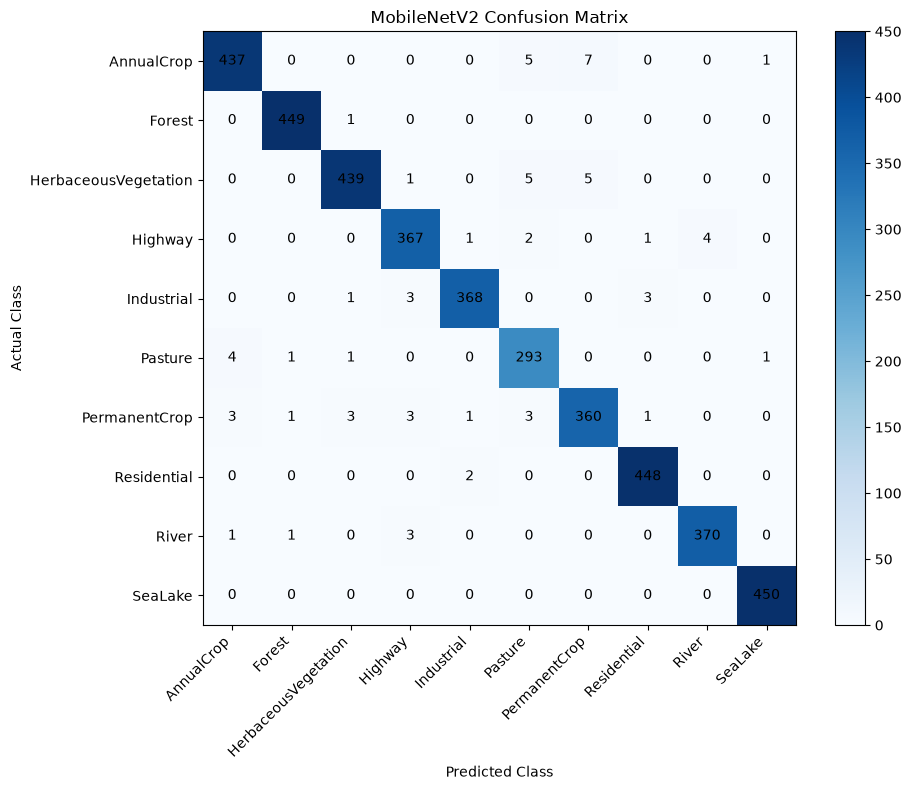

In [2]:
plt.figure(figsize=(10, 8))
plt.imshow(cm.values, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(cm.columns)), cm.columns, rotation=45, ha="right")
plt.yticks(range(len(cm.index)), cm.index)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MobileNetV2 Confusion Matrix")

for i in range(len(cm.index)):
    for j in range(len(cm.columns)):
        plt.text(j, i, cm.iloc[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()


## 3. Misclassification Analysis

The model made 69 incorrect predictions. Agricultural classes showed the largest confusion: 36 of the 69 mistakes are among AnnualCrop, PermanentCrop, Pasture and HerbaceousVegetation. A likely reason is similar vegetation patterns (we looked at examples but did not test this).


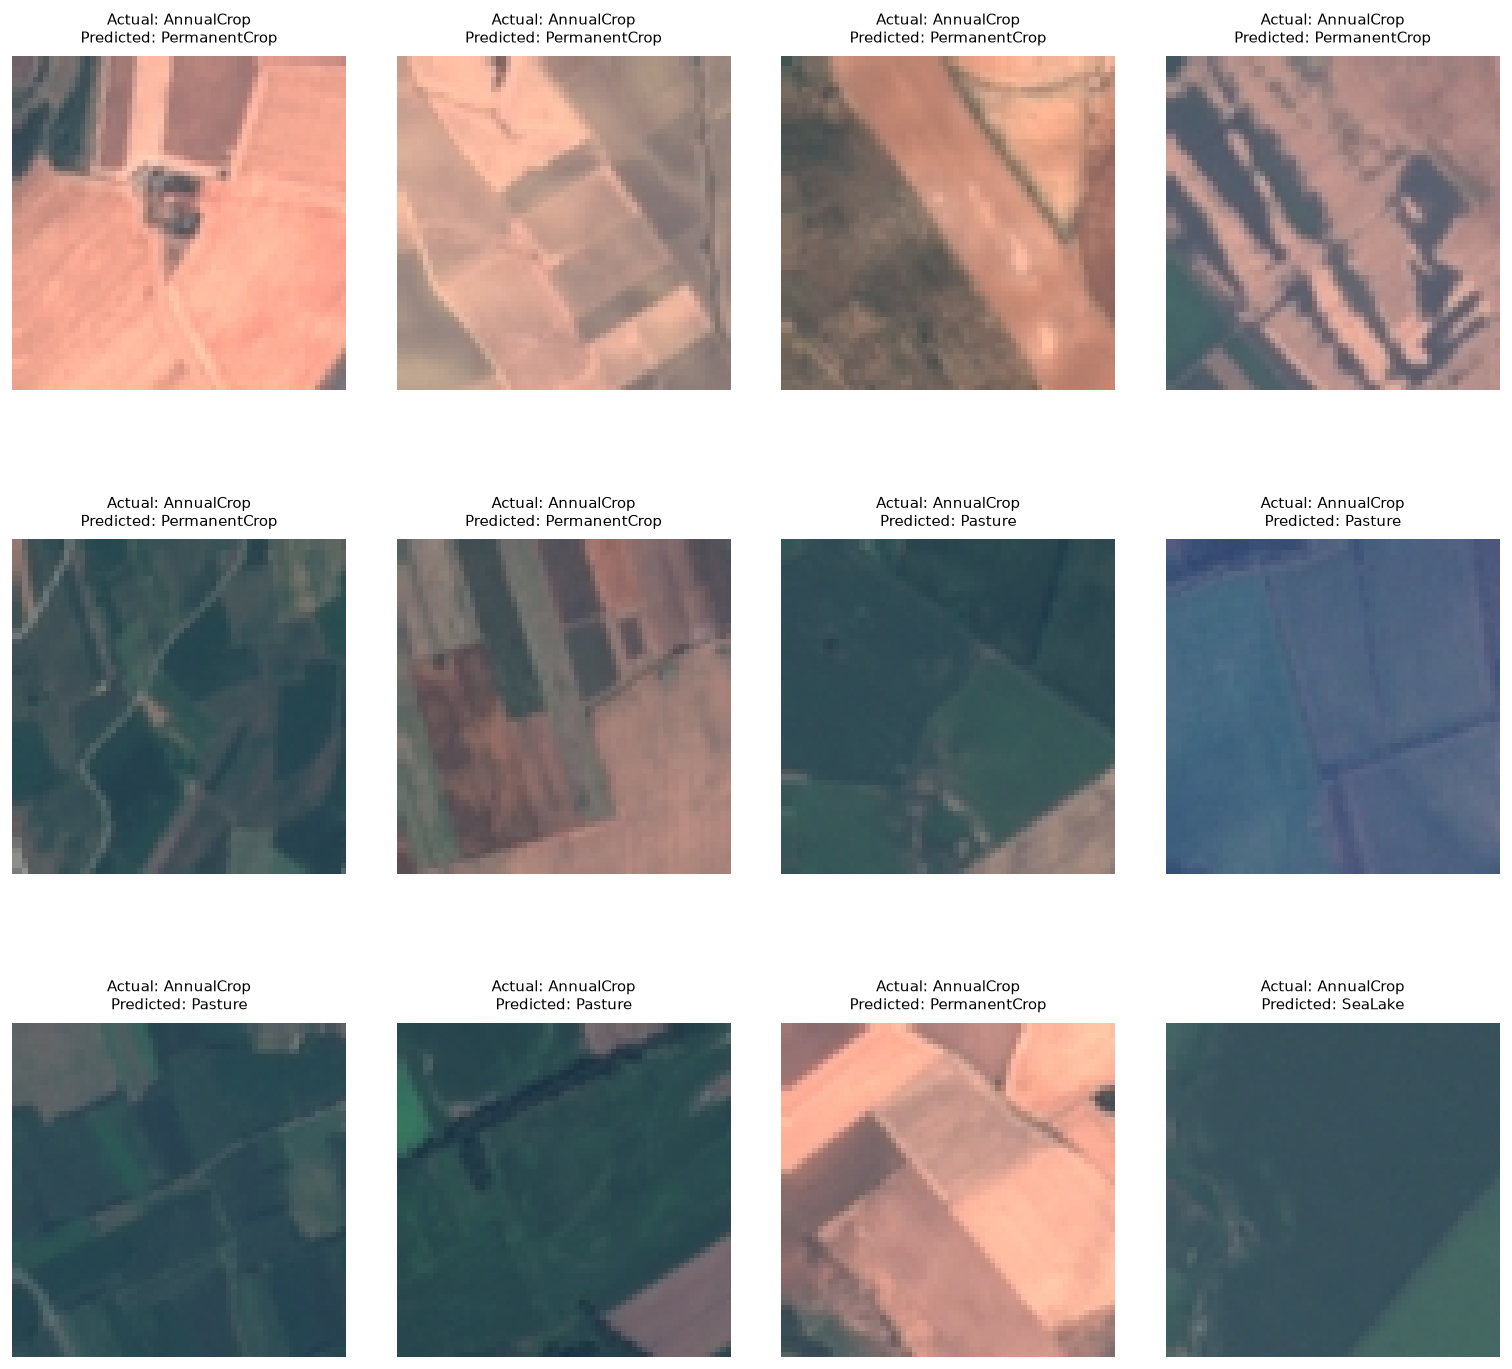

In [3]:
display(Image(filename=str(RESULTS / "misclassified_images_grid.png")))


### 3.1 Confused Class Pair Examples

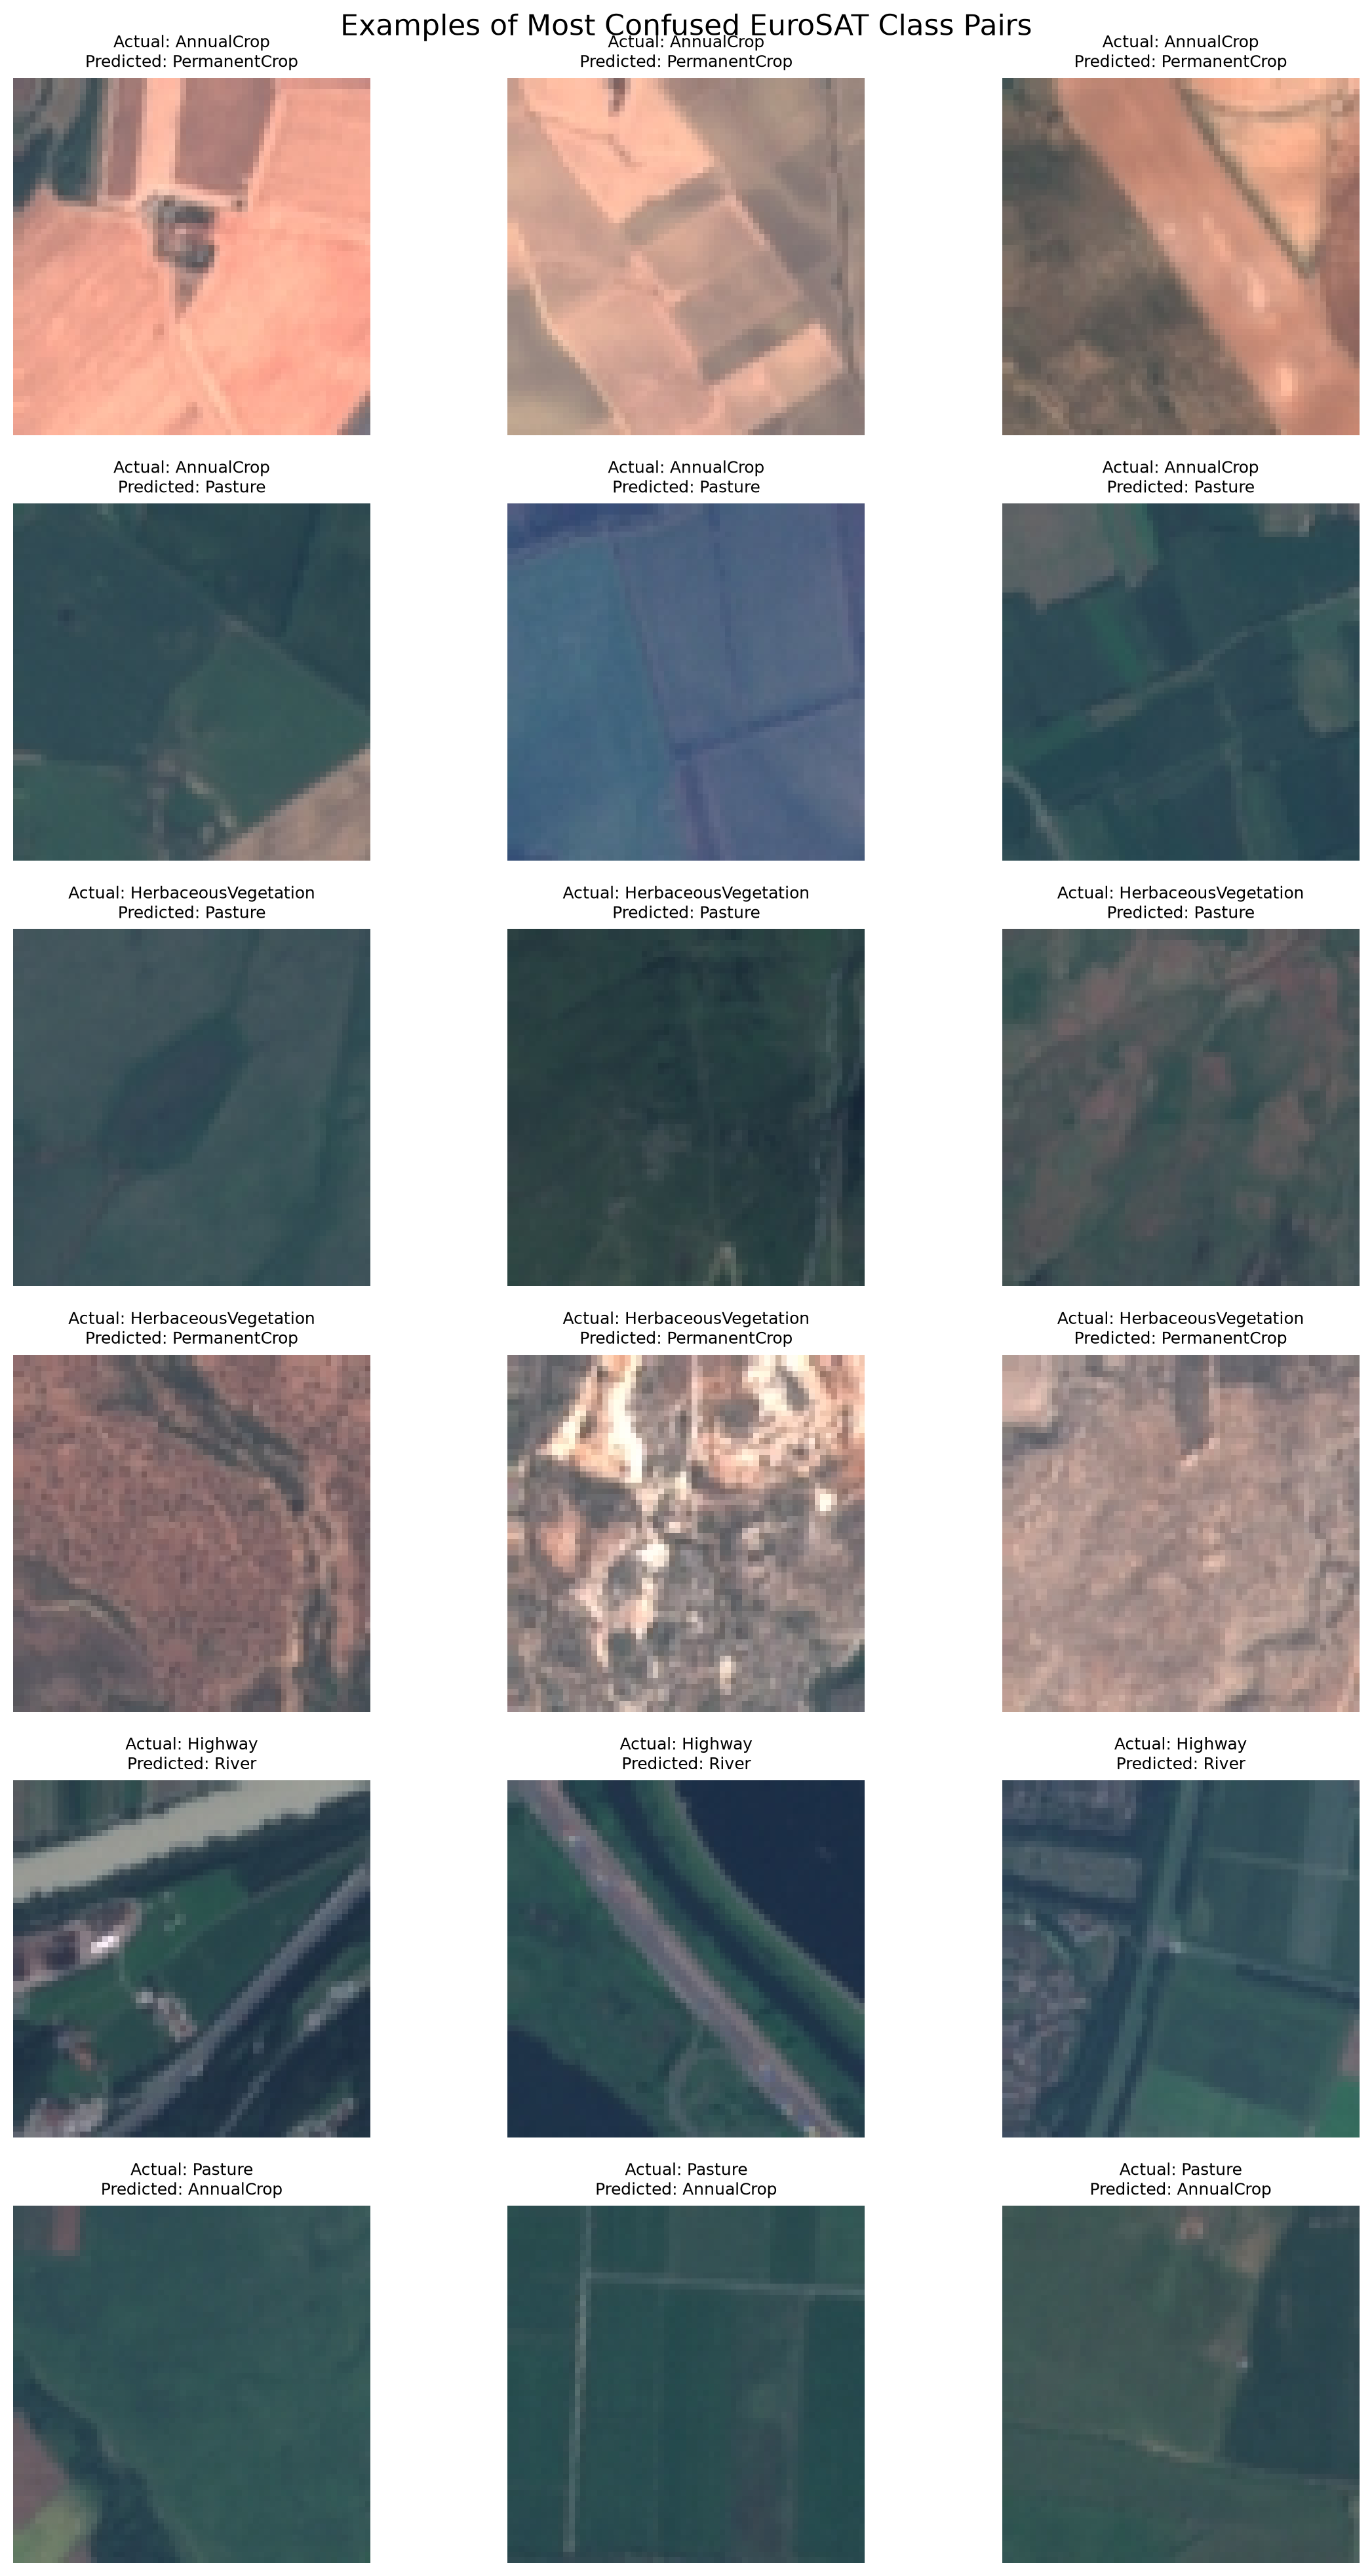

In [4]:
display(Image(filename=str(FIGURES / "confusion_pair_examples.png")))


## 4. Grad-CAM Explainability

**Read this section together with 5.1.** On this model the heat maps are only 2 x 2 cells and mostly hot in the lower-right, so they are pictures to look at, not proof of what the model sees.

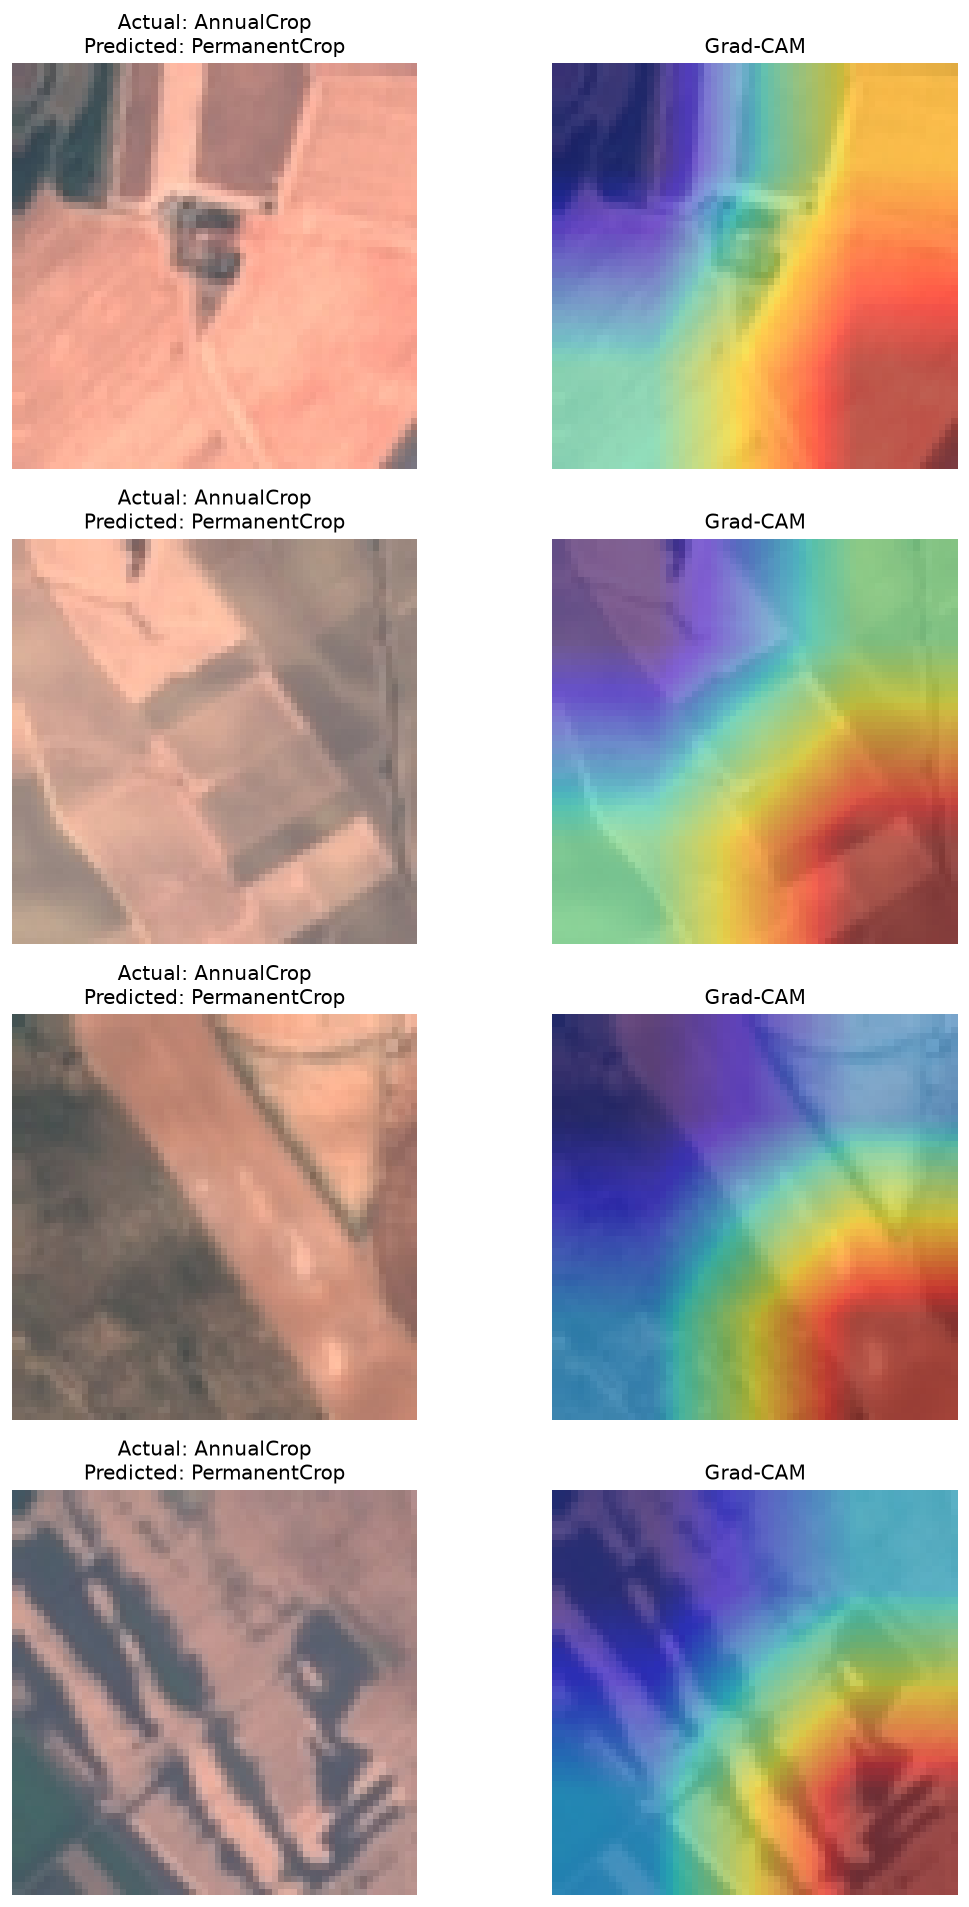

In [5]:
display(Image(filename=str(FIGURES / "gradcam_examples.png")))


### 4.1 Grad-CAM for All 10 Classes

Grad-CAM examples include correctly classified and misclassified images across the 10 EuroSAT classes. Most heat maps are hot in the lower-right part of the image, whatever the image shows (see 5.1).


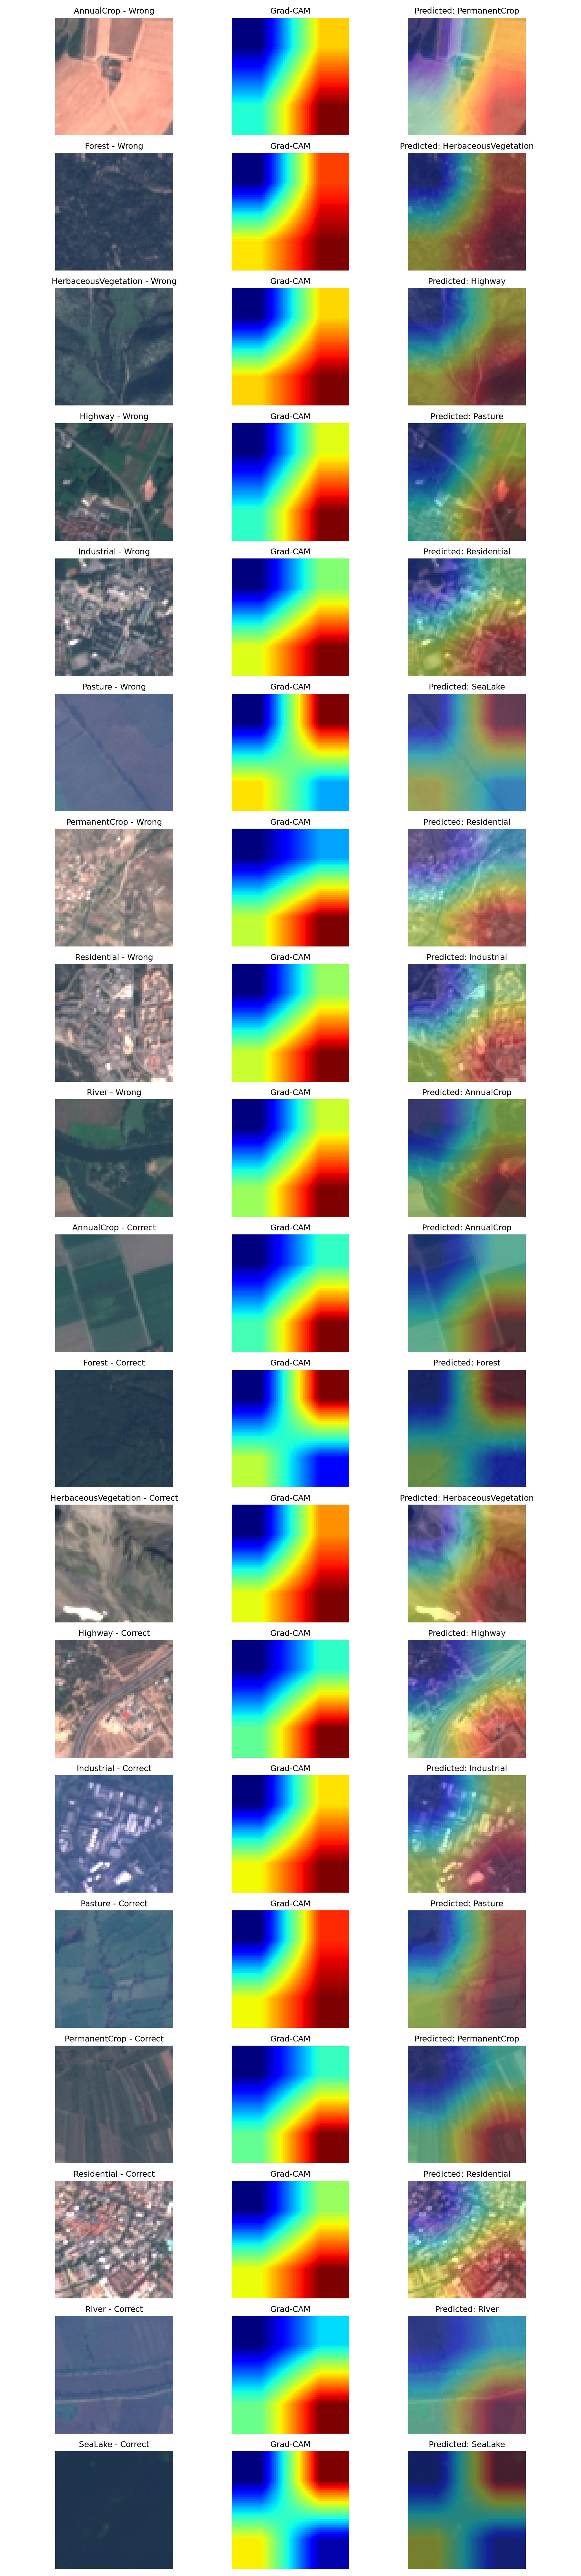

In [6]:
display(Image(filename=str(FIGURES / "gradcam_all_classes.png")))


## 5. Grad-CAM Confidence-Drop Experiment

This experiment has **no control** (no coldest-area or random-area patch), so a small drop alone does not show that the highlighted area matters. The control is in 5.1.

,path,class_name,original_confidence,masked_confidence,confidence_drop
0,eurosat/2750/Residential/Residential_136.jpg,Residential,0.999385,0.964483,0.034902
1,eurosat/2750/AnnualCrop/AnnualCrop_1877.jpg,AnnualCrop,0.998439,0.997943,0.000496
2,eurosat/2750/Industrial/Industrial_529.jpg,Industrial,0.999926,0.999956,-0.000029
3,eurosat/2750/PermanentCrop/PermanentCrop_1016.jpg,PermanentCrop,0.999930,0.997589,0.002342
4,eurosat/2750/Residential/Residential_900.jpg,Residential,1.000000,0.999996,0.000004


Number of evaluated images: 50


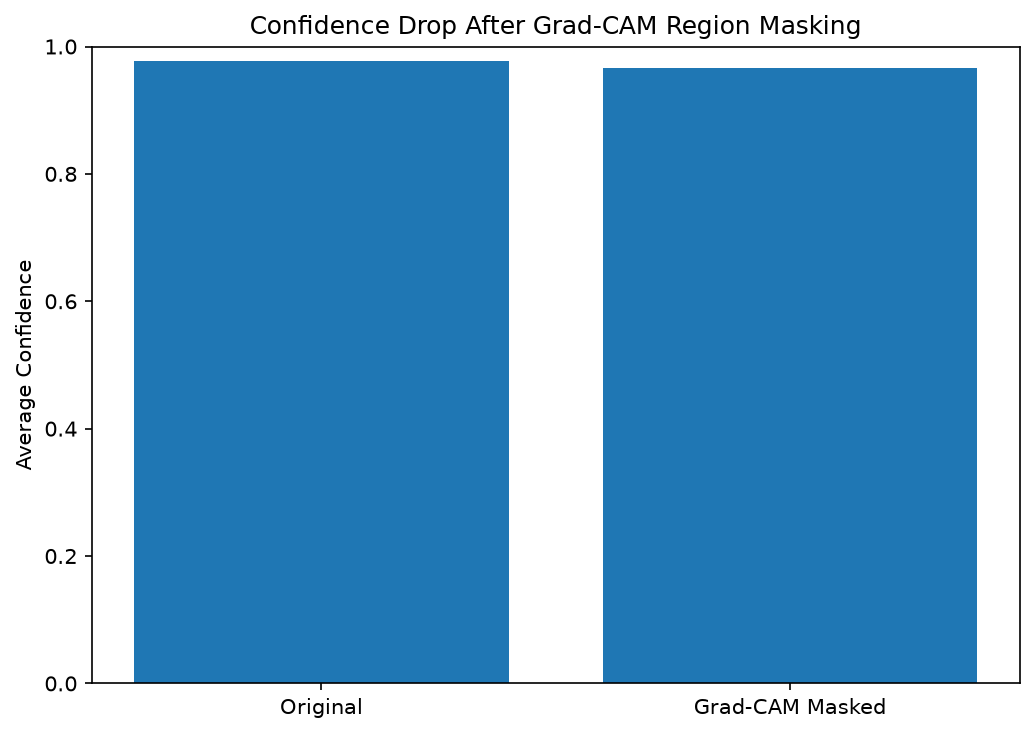

In [7]:
confidence = pd.read_csv(RESULTS / "gradcam_confidence_drop.csv")
display(confidence.head())
print("Number of evaluated images:", len(confidence))
display(Image(filename=str(FIGURES / "gradcam_confidence_drop.png")))


### 5.1 Control experiment (added by Nitin with Claude)

`python -m src.gradcam_sanity_check` hides 25% of the pixels (one solid patch) in 200 test images: the hottest area, the coldest area, or a random 32 x 32 square, and measures the fall in confidence. It also counts which quarter of the heat map is hottest. If Grad-CAM were meaningful, hiding the hottest area should hurt clearly more than hiding the coldest.

In [8]:
check = pd.read_csv(RESULTS / 'gradcam_sanity_check.csv')
summary = pd.DataFrame({
    'mean confidence drop': [check[f'drop_{n}'].mean() for n in ('hottest', 'coldest', 'random_square')],
    'prediction changed (of %d)' % len(check): [int(check[f'changed_{n}'].sum()) for n in ('hottest', 'coldest', 'random_square')],
}, index=['hottest 25%', 'coldest 25%', 'random 32 x 32 square']).round(3)
display(summary)
print('Hottest quarter of the heat map:')
print(check['hottest_quadrant'].value_counts().to_string())

,mean confidence drop,prediction changed (of 200)
hottest 25%,0.064,14
coldest 25%,0.061,14
random 32 x 32 square,0.089,17


Hottest quarter of the heat map:
hottest_quadrant
bottom-right    160
top-right        36
bottom-left       4


Hiding the hottest area hurts no more than hiding the coldest one, and the hottest quarter is the bottom-right in 80% of the images. So the heat maps do not identify a more important part of the image on this model.

## 6. t-SNE Feature Visualization

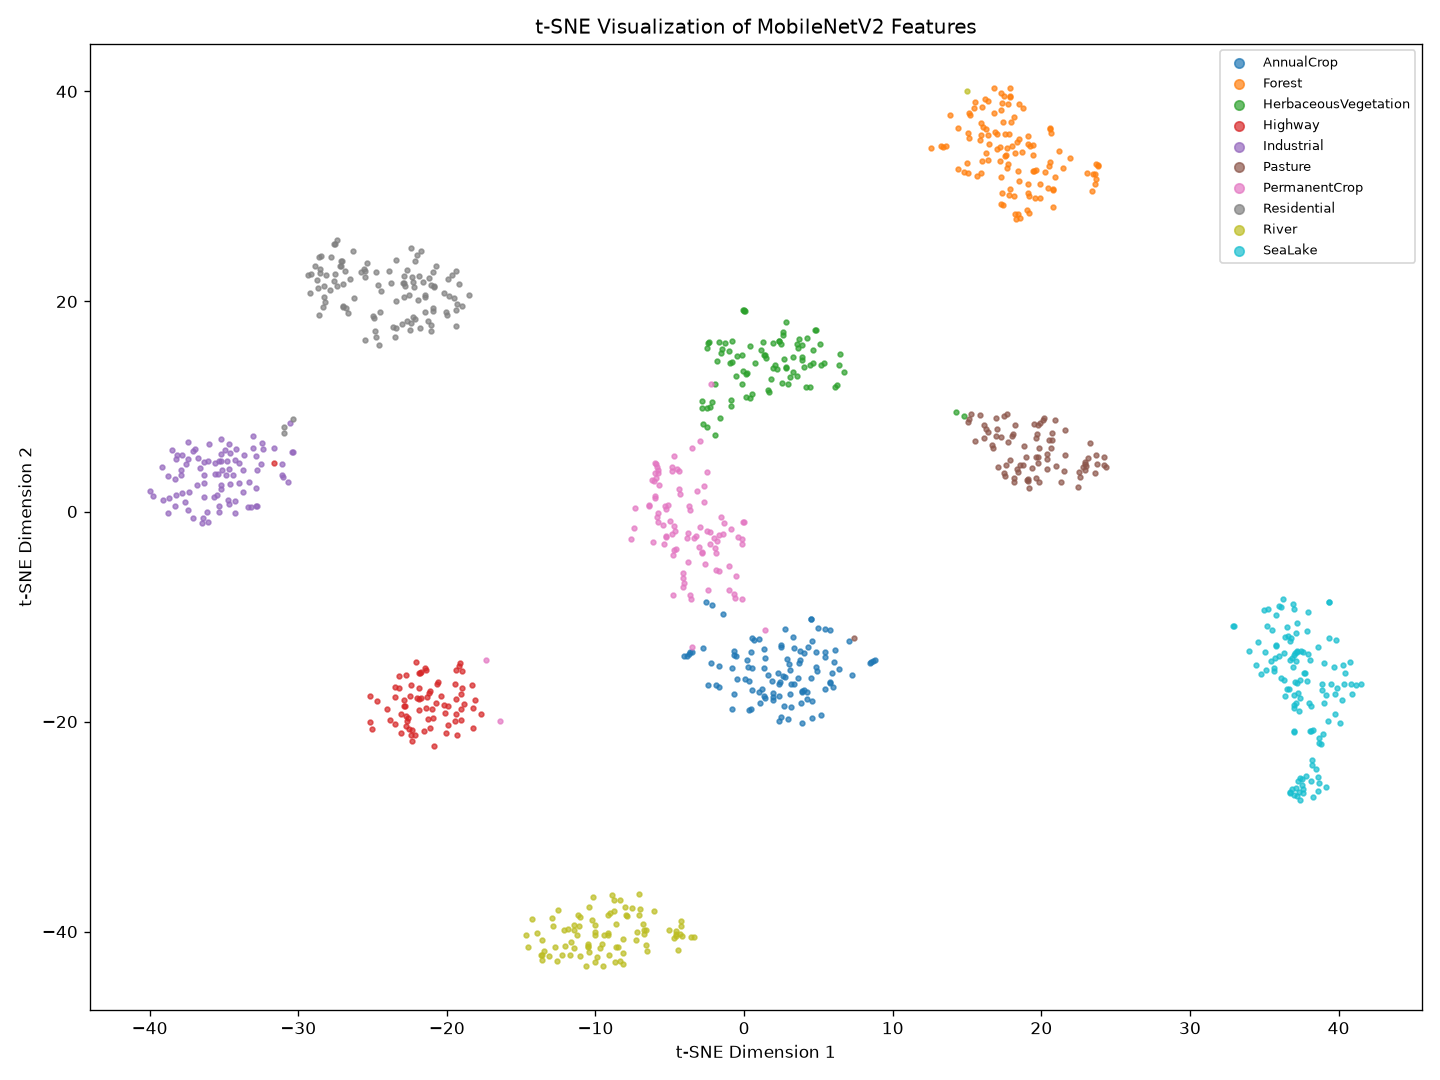

In [9]:
display(Image(filename=str(FIGURES / "mobilenet_v2_tsne.png")))


## 7. Data-Efficiency Experiment

Additional scratch CNN experiments were performed with seed 4 at 5%, 10%, and 25% training-data fractions.


In [10]:
metrics = pd.read_csv(RESULTS / "metrics.csv")
display(metrics[metrics["seed"] == 4])


,model,fraction,seed,accuracy,macro_f1
45,scratch_cnn,0.05,4,0.746914,0.739583
46,scratch_cnn,0.10,4,0.816790,0.809178
47,scratch_cnn,0.25,4,0.874321,0.868068


## 8. Conclusion

MobileNetV2 achieved 98.30% test accuracy and 98.20% Macro-F1. Error analysis identified confusion among visually similar agricultural classes. Grad-CAM was too coarse to explain single predictions (control experiment 5.1), the confidence-drop masking only makes sense together with that control, and t-SNE showed 10 clear groups of learned features.

### Limitations
- Grad-CAM here is very coarse (2 x 2 cells) and mostly points to the lower-right, so it is not evidence of model reasoning.
- Masking can introduce artificial image patterns.
- t-SNE does not preserve every original feature relationship.
- Results may not generalize to other satellite datasets.
